# Prosody-Dependency Distributional Analysis

This notebook merges the prosodic feature extraction logic with dependency-category overlap analysis. It builds a co-occurrence matrix of `(lemma, POS, dep_relation)` against a mix of **syntactic** and **prosodic** features extracted from the SUD-French-Rhapsodie treebank.

From that matrix we derive three parallel views — syntactic-only, prosodic-only, and combined — and use each to compute:

1. **Similarity scores** between lexical units
2. A **per-unit purity / entropy / rival-category** score based on the `dep_relation`
3. **Stability and Intruder matrices** (how dependency relations bleed into each other)
4. **Bridge words** — units whose neighbourhood pulls them toward a different dependency relation
5. **Pulling features** — the features responsible for that pull
6. A global **weighted-average stability (WAS)** for each feature space.

In [1]:
import sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml
from scipy.stats import entropy as shannon_entropy
from sklearn.metrics.pairwise import cosine_similarity

# ── Paths ──────────────────────────────────────────────────────────────────
TOD_PATH      = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/tod"
GREX_PATH     = "/Users/madalina/Documents/M2TAL/stage/grex/grex2"
TREEBANK_PATH = "/Users/madalina/Documents/PHD/code/data/SUD_French-Rhapsodie/prosody_pauses"
PATTERNS_FILE = "/Users/madalina/Documents/M2TAL/stage/check_coherent_labels/scripts/3. probability_matrix/patterns_all_nodes_prosody_deps.txt"

# Pattern to capture X and its head Y to extract the dependency relation e
GREW_PATTERN  = "pattern{X[upos<>PUNCT]; Y[upos<>PUNCT] ; e:Y->X}"
STRIP_DEPREL_SUBTYPES = True

EXCLUDED_FEATURE_PATTERNS = [r"X:own:", r"Y:child:", r"Y:next:", r"Y:parent:", r"Y:prev:", r"Coconstruct="]
INCLUDED_FEATURE_PATTERNS = []
# ── Bring third-party packages onto the path ───────────────────────────────
for p in (TOD_PATH, GREX_PATH):
    if p not in sys.path:
        sys.path.insert(1, p)

import pyximport
pyximport.install()
import grewpy
from grewpy import Corpus, CorpusDraft, Request
import tod.corpus
import grex.data
import grex.utils
import grex.features
import grex.data_prosody

grewpy.set_config("sud")


connected to port: 49162


In [2]:
# ── Drop entirely: redundant, unreliable, or too fine-grained ─────────────
FEATURES_TO_DROP = {
    'MeanF0', 'MeanF0Step', 'AvgAmplitude', 'MaxAmplitude', 'SylForm',
    'AlignBegin', 'AlignEnd', 'pauseID', 'BeforeMeanF0', 'BeforeMeanF0Step',
    'BeforeAvgAmplitude', 'NextMeanF0', 'NextMeanF0Step', 'NextAvgAmplitude',
    'Semiton', 'Overlap', 'Loc', 'Glo', 'Backchannel',
}

# ── Bin into 3 quantile-based categories ──────────────────────────────────
FEATURES_TO_BIN = {
    'SemitonesFromUtteranceMean', 'Duration', 'BeforeSemitonesFromUtterance',
    'NextSemitonesFromUtterance', 'BeforeDuration', 'NextDuration',
    'BeforeSemiton', 'NextSemiton', 'NextSemitonsFromUtterance',
}

BIN_LABELS = {
    'SemitonesFromUtteranceMean':   ['F0_low',       'F0_mid',       'F0_high'],
    'Duration':                     ['Dur_short',    'Dur_mid',      'Dur_long'],
    'BeforeSemitonesFromUtterance': ['BeforeF0_low', 'BeforeF0_mid', 'BeforeF0_high'],
    'NextSemitonesFromUtterance':   ['NextF0_low',   'NextF0_mid',   'NextF0_high'],
}

def _normalise_duration(value_str):
    try:
        v = float(value_str)
    except (ValueError, TypeError):
        return None
    if v == 0.0:
        return None
    return v * 1000 if v < 10 else v

def _is_sentinel(value_str):
    try:
        return float(value_str) == 0.0
    except (ValueError, TypeError):
        return False

def _feature_name(key):
    return key[-1]


In [3]:
# ── SLAM3 contour decomposition ───────────────────────────────────────────
# The *Tone features (FootTone, GroupTone, PackageTone, Period_tone) encode
# pitch contours compositionally:
#
#     [start_pitch][end_pitch]            -- no salient peak (2 chars)
#     [start_pitch][end_pitch][peak][tier] -- with salient peak (4 chars)
#
# pitch ∈ {L, l, m, h, H}  (5 ordinal levels: very low → very high)
# tier  ∈ {1, 2, 3}        (which syllabic tier carries the peak)
# Plus the special atomic value 'Pause'.
#
# Treating these as opaque strings gives ~300 sparse one-hot columns per
# *Tone feature. Decomposing into {start, end, peak, tier, has_peak,
# direction, magnitude} yields ~5 dense sub-features per token instead.

SLAM_TONE_FEATURES = {'FootTone', 'GroupTone', 'PackageTone', 'Period_tone'}

# Ordinal mapping used to derive direction & magnitude.
_PITCH_LEVELS = {'L': 1, 'l': 2, 'm': 3, 'h': 4, 'H': 5}
_TIERS = {'1', '2', '3'}


def _parse_slam(label):
    """Parse a SLAM3 contour string into its components.

    Returns a dict {pause, start, end, peak, tier} or None if the label
    doesn't match the SLAM3 grammar (silently skipped downstream).
    """
    if label == 'Pause':
        return {'pause': True, 'start': None, 'end': None,
                'peak': None, 'tier': None}

    if (len(label) == 2
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': None, 'tier': None}

    if (len(label) == 4
            and label[0] in _PITCH_LEVELS and label[1] in _PITCH_LEVELS
            and label[2] in _PITCH_LEVELS and label[3] in _TIERS):
        return {'pause': False, 'start': label[0], 'end': label[1],
                'peak': label[2], 'tier': label[3]}

    return None


def _slam_subfeatures(prefix, label):
    """Yield 'sub-feature=value' strings derived from a SLAM3 contour label.

    `prefix` is the path up to and including the *Tone name,
    e.g. 'node:X:child:GroupTone'. Sub-features become
    'node:X:child:GroupTone:start=H', 'node:X:child:GroupTone:direction=rise', …
    """
    parsed = _parse_slam(label)
    if parsed is None:
        return

    if parsed['pause']:
        yield f"{prefix}:pause=True"
        return

    s, e = parsed['start'], parsed['end']
    yield f"{prefix}:start={s}"
    yield f"{prefix}:end={e}"

    # Direction & magnitude on the ordinal pitch scale.
    delta = _PITCH_LEVELS[e] - _PITCH_LEVELS[s]
    if delta > 0:
        direction = 'rise'
    elif delta < 0:
        direction = 'fall'
    else:
        direction = 'flat'
    yield f"{prefix}:direction={direction}"
    yield f"{prefix}:magnitude={abs(delta)}"

    if parsed['peak'] is not None:
        yield f"{prefix}:has_peak=True"
        yield f"{prefix}:peak={parsed['peak']}"
        yield f"{prefix}:tier={parsed['tier']}"
    else:
        yield f"{prefix}:has_peak=False"

In [5]:
def collect_continuous_values(all_data_items):
    collector = {f: [] for f in FEATURES_TO_BIN}
    for _, _, features in all_data_items:
        for key, value in features.items():
            fname = _feature_name(key)
            if fname not in FEATURES_TO_BIN:
                continue
            values = value if isinstance(value, set) else {value}
            for v in values:
                if fname == 'Duration':
                    norm = _normalise_duration(v)
                    if norm is not None:
                        collector['Duration'].append(norm)
                elif not _is_sentinel(v):
                    try:
                        collector[fname].append(float(v))
                    except (ValueError, TypeError):
                        pass
    return collector

def compute_thresholds(collector, n_bins=3):
    thresholds = {}
    for fname, values in collector.items():
        if not values:
            continue
        arr = np.array(values)
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
        thresholds[fname] = np.quantile(arr, quantiles).tolist()
    return thresholds

def _bin_value(fname, value_str, thresholds):
    if fname not in thresholds or _is_sentinel(value_str):
        return None
    if fname == 'Duration':
        v = _normalise_duration(value_str)
    else:
        try:
            v = float(value_str)
        except (ValueError, TypeError):
            return None
    if v is None:
        return None
    bounds = thresholds[fname]
    labels = BIN_LABELS.get(fname, [f'{fname}_Q1', f'{fname}_Q2', f'{fname}_Q3'])
    for i, b in enumerate(bounds):
        if v <= b:
            return labels[i]
    return labels[-1]

def format_features(features, thresholds):
    """Turn a feature dict into a list of 'k1:k2:...:kn=value' strings.

    Continuous features are binned; dropped features are skipped.
    """
    result = []
    for key, value in features.items():
        fname = _feature_name(key)
        prefix = ':'.join(key)

        if fname in FEATURES_TO_DROP:
            continue

        if fname in FEATURES_TO_BIN:
            values = value if isinstance(value, set) else {value}
            for v in values:
                label = _bin_value(fname, v, thresholds)
                if label is not None:
                    result.append(f"{prefix}={label}")
            continue

        # SLAM3 contour features: decompose into structural sub-features.
        if fname in SLAM_TONE_FEATURES:
            values = value if isinstance(value, set) else {value}
            for v in values:
                result.extend(_slam_subfeatures(prefix, v))
            continue


        # Categorical: keep as-is.
        if isinstance(value, set):
            for v in value:
                result.append(f"{prefix}={v}")
        else:
            result.append(f"{prefix}={value}")

    return result

def _filter_features(features, excluded_patterns=None, included_patterns=None):
    import re
    out = []
    for feature in features:
        if excluded_patterns and any(re.search(p, feature) for p in excluded_patterns):
            continue
        if included_patterns and not any(re.search(p, feature) for p in included_patterns):
            continue
        out.append(feature)
    return out


In [6]:
import json
def _parse_edge_label(label_json: str) -> str:
        """Convert grew's edge label JSON string into a readable relation string.

        grew represents UD/SUD labels as a JSON dict where keys "1", "2", "3"
        encode the level (relation, subtype, sub-subtype). We re-join them with
        ':' to recover the standard surface form.

        Examples:
            '{"1":"obl","2":"mod"}'  -> 'obl:mod'
            '{"1":"nsubj"}'          -> 'nsubj'
            '{"1":"comp","2":"obj"}' -> 'comp:obj'
            '"appos"'                -> 'appos'
        """
        parsed = json.loads(label_json)
        
        # If it's a simple string (e.g., '"appos"'), json.loads returns str, not dict
        if isinstance(parsed, str):
            return parsed
        
        # Otherwise it's a dict with numeric keys "1", "2", etc. Ignore extra metadata keys.
        sorted_keys = sorted(
            (k for k in parsed.keys() if k.isdigit()),
            key=int,
        )
        return ":".join(parsed[k] for k in sorted_keys)

In [7]:
min_dep_occurrences = 5
corpus = grewpy.Corpus(TREEBANK_PATH)
draft  = grewpy.CorpusDraft(corpus)

request = grewpy.Request(GREW_PATTERN) \
    .without("X[InIdiom=Yes]") \
    .without("X[Idiom=Yes]") \
    .without("X[InTitle=Yes]") \
    .without("X[Title=Yes]") \
    .without("X[Scrap=Yes]") \
    .without("X[Foreign]") \
    .without("X[Lang]") \
    .without("X-[fixed]->Y") \
    .without("Y-[flat:name]->X") \
    .without("Y-[goeswith]->X")

# Cluster by lemma and dependency relation label
all_matches = corpus.search(request, clustering_parameter=["X.lemma", "e.label"])

dep_relation_totals = {}
for lemma, dep_dict in all_matches.items():  # type: ignore
    for edge_label_json, match_list in dep_dict.items():
        dep_relation = _parse_edge_label(edge_label_json)
        dep_relation_totals[dep_relation] = (
            dep_relation_totals.get(dep_relation, 0) + len(match_list)
        )

rare_deps = {
    dep for dep, count in dep_relation_totals.items()
    if count < min_dep_occurrences
}
if rare_deps:
    print(f"Dropping {len(rare_deps)} rare dep relations "
            f"(< {min_dep_occurrences} total occurrences): "
            f"{sorted(rare_deps)}")


Dropping 3 rare dep relations (< 5 total occurrences): ['conj:obj', 'orphan', 'parataxis']


In [9]:
matches = {}
for lemma, dep_dict in all_matches.items():  # type: ignore
    for edge_label_json, match_list in dep_dict.items():
        dep_relation = _parse_edge_label(edge_label_json)
        matches[(lemma, dep_relation)] = match_list
sent_id_to_sentence = {
            draft[i].meta["sent_id"]: draft[i].features for i in range(len(draft))  # type: ignore
        }

In [10]:
# Re-key by (lemma, POS, dep) and filter low frequencies.
match_upos = {}
for (lemma, dep_relation), value in matches.items():
    for m in value:
        match_sent_id = m["sent_id"]
        match_node_index = str(m["matching"]["nodes"]["X"])
        if match_sent_id in sent_id_to_sentence:
            current_sentence_features = sent_id_to_sentence[match_sent_id]
            if match_node_index in current_sentence_features.keys():
                current_token_features = current_sentence_features[match_node_index]
                if "ExtPos" in current_token_features:
                    match_upos.setdefault(
                        (lemma, current_token_features["ExtPos"], dep_relation), []
                    ).append(m)
                else:
                    try:
                        match_upos.setdefault(
                            (lemma, current_token_features["upos"], dep_relation), []
                        ).append(m)
                    except KeyError:
                        print(f"WARNING: Token with lemma '{lemma}' in sentence "
                                f"'{match_sent_id}' does not have a 'upos' feature.")

    # Re-filter: splitting by pos may have pushed some buckets under threshold.
    # (We already filtered before splitting by pos, but the same logic from the
    # original applies — a (lemma, dep) group might split across two POS tags.)
# new_match_upos = {}
# for key, value in match_upos.items():
#     if len(value) > 10:
#         new_match_upos[key] = value
# match_upos = new_match_upos

for key, value in match_upos.items():
    if len(value) < 10:
        print(f"WARNING: {key} has only {len(value)} occurrences but passed filtering!")


In [11]:
with open(PATTERNS_FILE) as f:
    config = yaml.load(f, Loader=yaml.Loader)

templates = grex.utils.FeaturePredicate.from_config(config["templates"])
feature_predicate = grex.utils.FeaturePredicate.from_config(
    config["features"], templates=templates,
)

all_data_items = []
for lex_unit, mts in match_upos.items():
    for match in mts:
        features = grex.data_prosody.extract_features(draft, match, feature_predicate)
        all_data_items.append((lex_unit, match, features))

In [10]:
print(f"Total (lex_unit, match, features) triples: {len(all_data_items)}")


Total (lex_unit, match, features) triples: 18375


In [21]:
collector  = collect_continuous_values(all_data_items)
thresholds = compute_thresholds(collector, n_bins=3)

print("Computed thresholds:")
for fname, bounds in thresholds.items():
    labels = BIN_LABELS.get(fname, ['Q1', 'Q2', 'Q3'])
    print(
        f"  {fname}: <{bounds[0]:.3f} → {labels[0]} | "
        f"<{bounds[1]:.3f} → {labels[1]} | ≥{bounds[1]:.3f} → {labels[2]}"
    )

# Drop 'own' features (the focused node's own attributes — they trivially
# determine its category and would dominate similarity).
EXCLUDED_FEATURE_PATTERNS = [r"X:own:", 'ExtPos', 'AttachTo=', 'Token2=', r"Y:child:", r"Y:next:", r"Y:parent:", r"Y:prev:", r"Coconstruct=", "Loc=", "direction=flat", "has_peak=False", "FootTone:pause", "GroupTone:pause", "PackageTone:pause", "Period_tone:pause", "ProminenceFinal=Pause", "ProminenceInitial=Pause"]
data = {k: [] for k in match_upos}
for lex_unit, _, features in all_data_items:
    formatted = _filter_features(
        format_features(features, thresholds),
        excluded_patterns=EXCLUDED_FEATURE_PATTERNS,
    )
    data[lex_unit].append(formatted)


Computed thresholds:
  NextSemiton: <-0.364 → Q1 | <1.076 → Q2 | ≥1.076 → Q3
  SemitonesFromUtteranceMean: <-1.348 → F0_low | <0.483 → F0_mid | ≥0.483 → F0_high
  BeforeSemitonesFromUtterance: <-1.088 → BeforeF0_low | <1.570 → BeforeF0_mid | ≥1.570 → BeforeF0_high
  NextSemitonsFromUtterance: <-1.250 → Q1 | <0.814 → Q2 | ≥0.814 → Q3
  BeforeSemiton: <-2.415 → Q1 | <1.506 → Q2 | ≥1.506 → Q3
  Duration: <134.000 → Dur_short | <204.000 → Dur_mid | ≥204.000 → Dur_long
  NextSemitonesFromUtterance: <-2.160 → NextF0_low | <-0.356 → NextF0_mid | ≥-0.356 → NextF0_high


In [49]:
unique_lemma    = sorted(set(data))
unique_features = sorted({feat for lists in data.values() for fs in lists for feat in fs})

idx2feature = {i: feat for i, feat in enumerate(unique_features)}
feature2idx = {feat: i for i, feat in idx2feature.items()}
idx2lexunit = {i: feat for i, feat in enumerate(unique_lemma)}
lexunit2idx = {feat: i for i, feat in idx2lexunit.items()}

print(f"Lexical units: {len(idx2lexunit)} | features: {len(idx2feature)}")


Lexical units: 5367 | features: 5676


In [23]:
idx2feature

{0: 'node:X:child:Case=Acc',
 1: 'node:X:child:Case=Dat',
 2: 'node:X:child:Case=Nom',
 3: 'node:X:child:Definite=Def',
 4: 'node:X:child:Definite=Ind',
 5: 'node:X:child:Foot=Begin',
 6: 'node:X:child:Foot=In',
 7: 'node:X:child:Foot=Last',
 8: 'node:X:child:Foot=Unique',
 9: 'node:X:child:FootTone:direction=fall',
 10: 'node:X:child:FootTone:direction=rise',
 11: 'node:X:child:FootTone:end=H',
 12: 'node:X:child:FootTone:end=L',
 13: 'node:X:child:FootTone:end=h',
 14: 'node:X:child:FootTone:end=l',
 15: 'node:X:child:FootTone:end=m',
 16: 'node:X:child:FootTone:has_peak=True',
 17: 'node:X:child:FootTone:magnitude=0',
 18: 'node:X:child:FootTone:magnitude=1',
 19: 'node:X:child:FootTone:magnitude=2',
 20: 'node:X:child:FootTone:magnitude=3',
 21: 'node:X:child:FootTone:magnitude=4',
 22: 'node:X:child:FootTone:peak=H',
 23: 'node:X:child:FootTone:peak=L',
 24: 'node:X:child:FootTone:peak=h',
 25: 'node:X:child:FootTone:peak=l',
 26: 'node:X:child:FootTone:peak=m',
 27: 'node:X:child

In [50]:
co_occurrence_matrix = np.zeros((len(idx2lexunit), len(idx2feature)))
for lex_unit, feature_lists in data.items():
    for feature_list in feature_lists:
        for feature in feature_list:
            co_occurrence_matrix[lexunit2idx[lex_unit], feature2idx[feature]] += 1

row_sums = co_occurrence_matrix.sum(axis=1)
feature_matrix = np.divide(
    co_occurrence_matrix,
    row_sums[:, np.newaxis],
    out=np.zeros_like(co_occurrence_matrix),
    where=row_sums[:, np.newaxis] != 0,
)

# ── Column-frequency filter ───────────────────────────────────────────────
# Drop feature columns that are non-zero on fewer than MIN_LEXUNITS lexical
# units. Such columns contribute mostly noise to cosine similarity (they look
# like spurious axes of variation between the few units that happen to use
# them) and bloat the matrix.
#
# Cosine similarity is scale-invariant, so we don't renormalise rows after
# dropping columns — within-row ratios are preserved.
MIN_LEXUNITS = 10

col_nonzero_per_lexunit = (co_occurrence_matrix > 0).sum(axis=0)
keep_cols = col_nonzero_per_lexunit >= MIN_LEXUNITS

n_before = feature_matrix.shape[1]
co_occurrence_matrix = co_occurrence_matrix[:, keep_cols]
feature_matrix       = feature_matrix[:, keep_cols]

# Rebuild the index lookups so they stay aligned with the matrix.
kept_features = [idx2feature[i] for i in range(n_before) if keep_cols[i]]
idx2feature   = {i: f for i, f in enumerate(kept_features)}
feature2idx   = {f: i for i, f in idx2feature.items()}

print(f"Dropped {n_before - int(keep_cols.sum())} columns "
      f"non-zero on <{MIN_LEXUNITS} lexical units.")
print(f"Remaining features: {int(keep_cols.sum())} / {n_before}")


PROSODIC_MARKERS = (
    'childSyl', 'prevSyl', 'nextSyl', 'Slope', 'Glo', 'Loc', 'Duration',
    'PitchRange', 'AvgHeight', 'Semiton', 'F0', 'Fused',
    # token-level prosodic structural annotations
    'Foot', 'Group', 'Package', 'Period',
    'Prominence', 'Hesitation', 'RhythmGroup', 'NextBreakLength', 'IU', 'Nucleus', 'TypePara', 'Layer=', 'TypeInherited', 'Truncated', 'Postnucleus', 'Prenucleus', 'Innucleus',
)
prosodic_mask = np.array([any(p in feat for p in PROSODIC_MARKERS) for feat in idx2feature.values()])
syntactic_mask = ~prosodic_mask

similarities = {
    "syntactic": cosine_similarity(feature_matrix[:, syntactic_mask]),
    "prosodic":  cosine_similarity(feature_matrix[:, prosodic_mask]),
    "combined":  cosine_similarity(feature_matrix),
}


Dropped 4566 columns non-zero on <10 lexical units.
Remaining features: 1110 / 5676


In [51]:
syntactic_features = [
    feat for i, feat in idx2feature.items()
    if syntactic_mask[i]
]

print(f"Syntactic features: {len(syntactic_features)}")
for feat in syntactic_features:
    print(feat)

Syntactic features: 256
node:X:child:Case=Acc
node:X:child:Case=Dat
node:X:child:Case=Nom
node:X:child:Definite=Def
node:X:child:Definite=Ind
node:X:child:Gender=Fem
node:X:child:Gender=Masc
node:X:child:Mood=Cnd
node:X:child:Mood=Imp
node:X:child:Mood=Ind
node:X:child:Mood=Sub
node:X:child:Number=Plur
node:X:child:Number=Sing
node:X:child:Person=1
node:X:child:Person=2
node:X:child:Person=3
node:X:child:Polarity=Neg
node:X:child:Poss=Yes
node:X:child:PronType=Art
node:X:child:PronType=Dem
node:X:child:PronType=Ind
node:X:child:PronType=Int
node:X:child:PronType=Neg
node:X:child:PronType=Prs
node:X:child:PronType=Rel
node:X:child:Tense=Fut
node:X:child:Tense=Imp
node:X:child:Tense=Pres
node:X:child:VerbForm=Fin
node:X:child:VerbForm=Inf
node:X:child:VerbForm=Part
node:X:child:rel_shallow=cc
node:X:child:rel_shallow=comp
node:X:child:rel_shallow=comp:aux
node:X:child:rel_shallow=comp:obj
node:X:child:rel_shallow=comp:obl
node:X:child:rel_shallow=comp:pred
node:X:child:rel_shallow=compou

In [46]:
idx2feature

{0: 'node:X:child:Case=Acc',
 1: 'node:X:child:Case=Dat',
 2: 'node:X:child:Case=Nom',
 3: 'node:X:child:Definite=Def',
 4: 'node:X:child:Definite=Ind',
 5: 'node:X:child:Foot=Begin',
 6: 'node:X:child:Foot=In',
 7: 'node:X:child:Foot=Last',
 8: 'node:X:child:Foot=Unique',
 9: 'node:X:child:FootTone:direction=fall',
 10: 'node:X:child:FootTone:direction=rise',
 11: 'node:X:child:FootTone:end=H',
 12: 'node:X:child:FootTone:end=L',
 13: 'node:X:child:FootTone:end=h',
 14: 'node:X:child:FootTone:end=l',
 15: 'node:X:child:FootTone:end=m',
 16: 'node:X:child:FootTone:has_peak=True',
 17: 'node:X:child:FootTone:magnitude=0',
 18: 'node:X:child:FootTone:magnitude=1',
 19: 'node:X:child:FootTone:magnitude=2',
 20: 'node:X:child:FootTone:magnitude=3',
 21: 'node:X:child:FootTone:magnitude=4',
 22: 'node:X:child:FootTone:peak=H',
 23: 'node:X:child:FootTone:peak=L',
 24: 'node:X:child:FootTone:peak=h',
 25: 'node:X:child:FootTone:peak=l',
 26: 'node:X:child:FootTone:peak=m',
 27: 'node:X:child

In [52]:
def _base(deprel):
    if STRIP_DEPREL_SUBTYPES and ":" in deprel:
        return deprel.split(":", 1)[0]
    return deprel

def _global_category_freqs(idx2lexunit):
    all_deps = [_base(lu[2]) for lu in idx2lexunit.values()]
    total = len(all_deps)
    return {dep: count / total for dep, count in Counter(all_deps).items()}

def compute_scores(similarity, idx2lexunit, category_freqs, sim_threshold=0.7, max_neighbours=20):
    scores = {}
    for idx, lex_unit in idx2lexunit.items():
        current_cat = _base(lex_unit[2])
        candidate_idx = np.where(similarity[idx] >= sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]
        if not neighbours:
            continue

        raw_weights = {}
        total_weight = 0.0
        for n_idx in neighbours:
            n_cat = _base(idx2lexunit[n_idx][2])
            w = similarity[idx][n_idx]
            raw_weights[n_cat] = raw_weights.get(n_cat, 0) + w
            total_weight += w

        norm_weights = {
            cat: (w / total_weight) / category_freqs[cat]
            for cat, w in raw_weights.items()
        }
        total = sum(norm_weights.values())
        p_norm = {cat: v / total for cat, v in norm_weights.items()}

        purity_score  = p_norm.get(current_cat, 0.0)
        entropy_score = shannon_entropy(list(p_norm.values()), base=2)

        rival_cat, rival_p = None, 0.0
        for cat, p in p_norm.items():
            if cat != current_cat and p > rival_p:
                rival_p, rival_cat = p, cat

        scores[lex_unit] = {
            "purity": purity_score,
            "entropy": entropy_score,
            "rival_category": rival_cat,
            "rival_weight_ratio": rival_p,
        }
    return scores


In [53]:
category_freqs = _global_category_freqs(idx2lexunit)
scores_by_space = {
    space: compute_scores(sim, idx2lexunit, category_freqs)
    for space, sim in similarities.items()
}
print({space: len(s) for space, s in scores_by_space.items()})


{'syntactic': 5250, 'prosodic': 2587, 'combined': 2222}


In [54]:
def build_matrices(similarity, idx2lexunit, category_freqs, excluded_deps=None, sim_threshold=0.7, max_neighbours=20):
    excluded_deps = set(excluded_deps or [])
    all_data = []
    for idx, lex_unit in idx2lexunit.items():
        current_cat = _base(lex_unit[2])
        candidate_idx = np.where(similarity[idx] >= sim_threshold)[0]
        neighbours = sorted(
            [i for i in candidate_idx if i != idx],
            key=lambda i: similarity[idx][i],
            reverse=True,
        )[:max_neighbours]
        if not neighbours:
            continue

        raw_weights = {}
        total_weight = 0.0
        for n_idx in neighbours:
            n_cat = _base(idx2lexunit[n_idx][2])
            w = similarity[idx][n_idx]
            raw_weights[n_cat] = raw_weights.get(n_cat, 0.0) + w
            total_weight += w

        norm_weights = {
            cat: (w / total_weight) / category_freqs[cat]
            for cat, w in raw_weights.items()
        }
        total = sum(norm_weights.values())
        p_norm = {cat: v / total for cat, v in norm_weights.items()}

        for cat, prob in p_norm.items():
            all_data.append({"Original": current_cat, "Neighbour": cat, "Weight": prob})

    df = pd.DataFrame(all_data)
    all_cats = sorted(set(df["Original"]) | set(df["Neighbour"]))
    matrix = (df.groupby(["Original", "Neighbour"])["Weight"]
                .sum().unstack(fill_value=0)
                .reindex(index=all_cats, columns=all_cats, fill_value=0))

    row_sums = matrix.sum(axis=1).replace(0, 1)
    stability_matrix = matrix.div(row_sums, axis=0)

    intruder_raw = stability_matrix.copy()
    np.fill_diagonal(intruder_raw.values, 0.0)
    row_sums_int = intruder_raw.sum(axis=1).replace(0, 1)
    intruder_matrix = intruder_raw.div(row_sums_int, axis=0)

    if excluded_deps:
        keep = [c for c in all_cats if c not in excluded_deps]
        stability_matrix = stability_matrix.loc[keep, keep]
        intruder_matrix  = intruder_matrix.loc[keep, keep]

    return stability_matrix, intruder_matrix

def plot_matrix(matrix, title):
    plt.figure(figsize=(14, 12))
    sns.heatmap(matrix, annot=True, cmap="YlOrRd", fmt=".2f")
    plt.title(title)
    plt.ylabel("Original Dep Relation")
    plt.xlabel("Rival Dep Relation")
    plt.show()


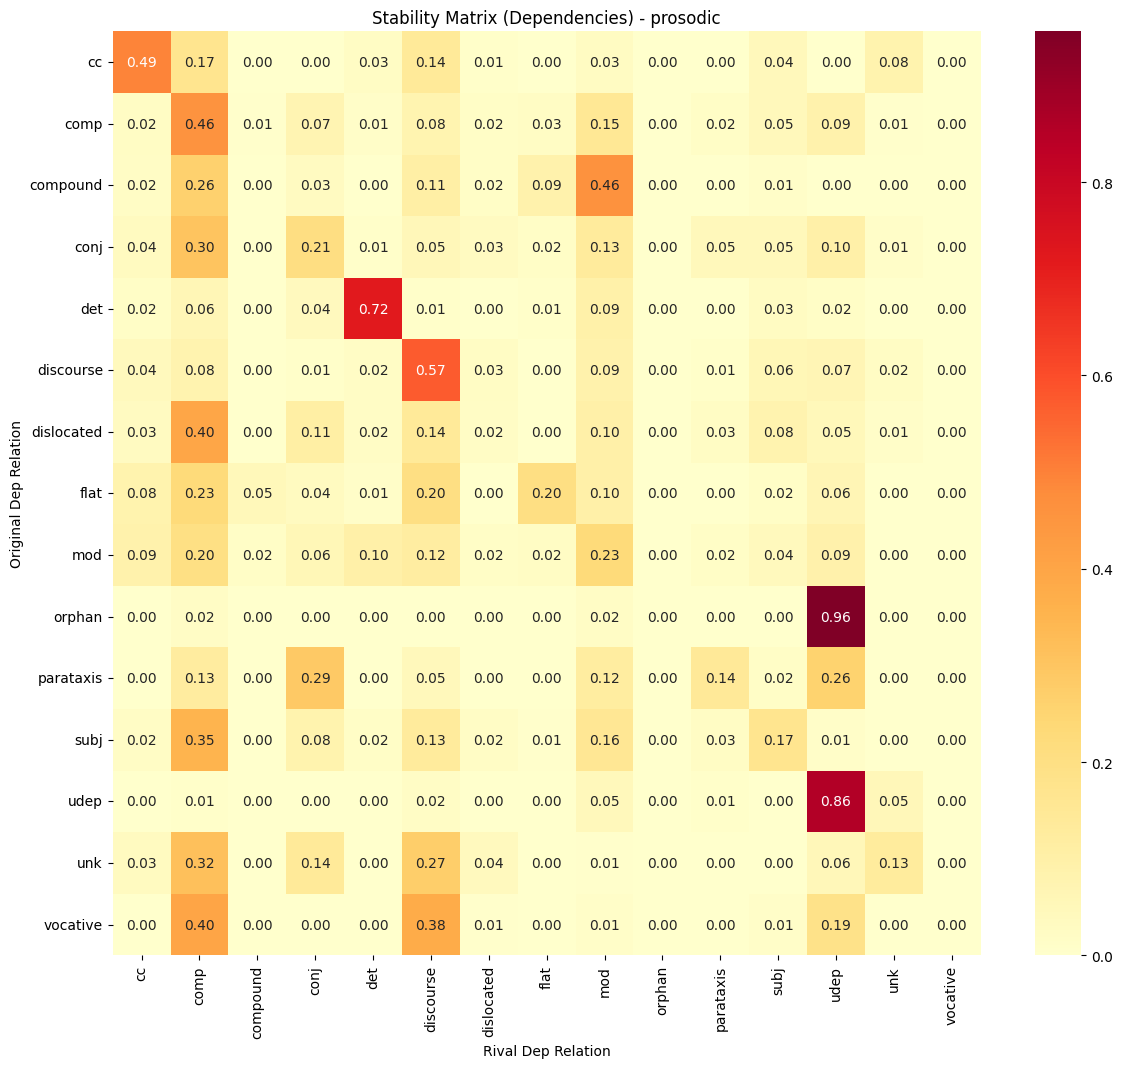

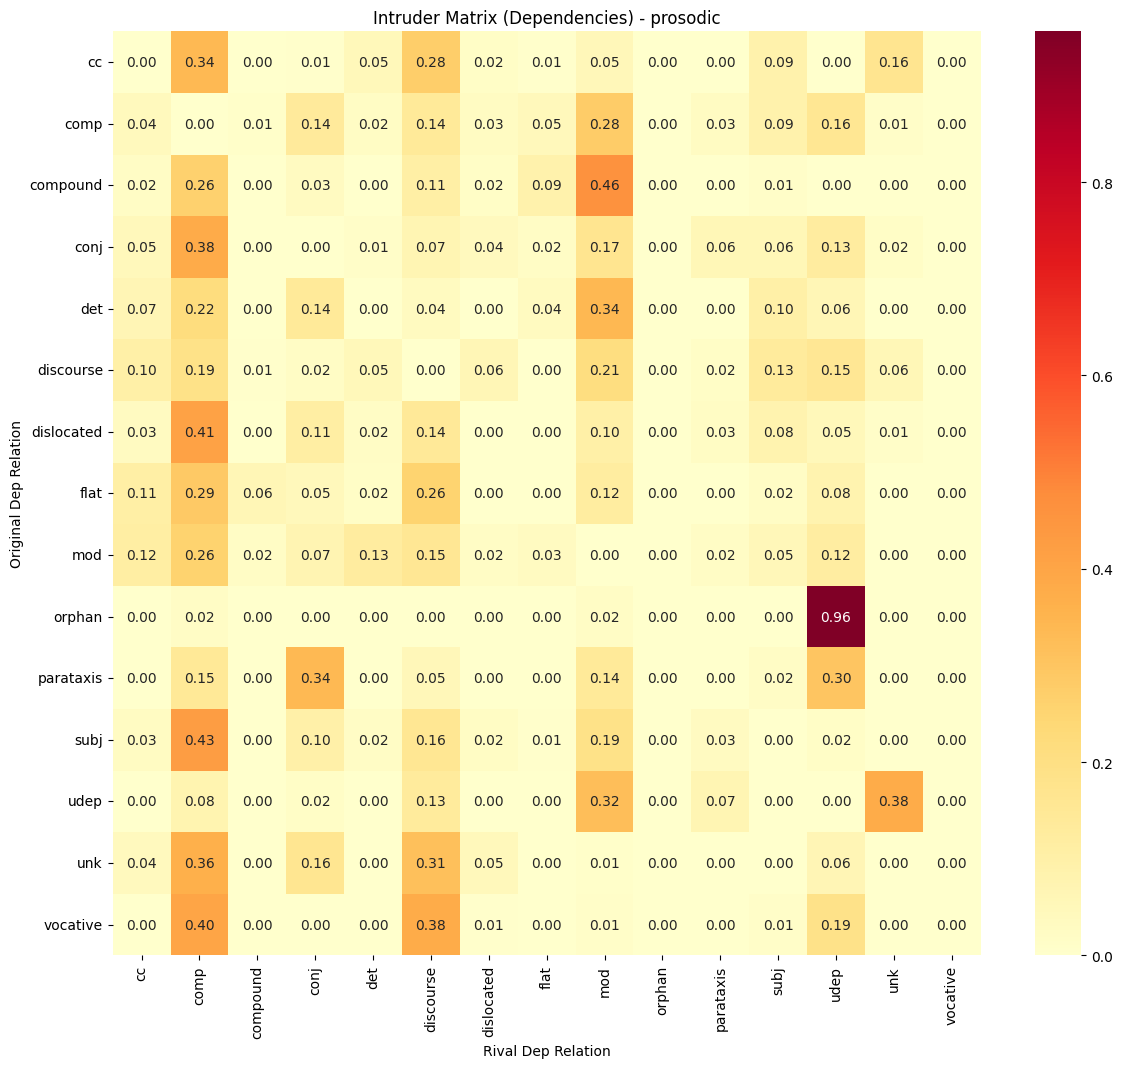

In [56]:
# Compute and plot stability matrices for a specific space
SPACE = "prosodic" # Change to "syntactic" or "prosodic" as needed
stability_matrix, intruder_matrix = build_matrices(similarities[SPACE], idx2lexunit, category_freqs)

plot_matrix(stability_matrix, f"Stability Matrix (Dependencies) - {SPACE}")
plot_matrix(intruder_matrix, f"Intruder Matrix (Dependencies) - {SPACE}")


In [57]:
def get_top_bridge_words(scores_dict, original_dep, rival_dep, top_n=100):
    matches = [
        {"lex_unit": lu, "lemma": lu[0], "pos": lu[1], "dep": lu[2],
         "purity": float(d["purity"]), "entropy": float(d["entropy"])}
        for lu, d in scores_dict.items()
        if _base(lu[2]) == original_dep and d["rival_category"] == rival_dep
    ]
    matches.sort(key=lambda x: 0.7 * x["purity"] - 0.3 * x["entropy"])
    return matches[:top_n]

def get_pulling_features(lex_unit, rival_dep, feature_matrix, similarity_matrix, 
                         idx2lexunit, lexunit2idx, idx2feature, feature2idx,  feature_mask=None,
                         sim_threshold=0.7, n_neighbors=20, top_k_features=20):
    unit_idx = lexunit2idx[lex_unit]
    lex_unit_vec = feature_matrix[unit_idx]
    candidate_idx = np.where(similarity_matrix[unit_idx] >= sim_threshold)[0]
    neighbours = sorted(
        [i for i in candidate_idx if i != unit_idx],
        key=lambda i: similarity_matrix[unit_idx][i],
        reverse=True,
    )[:n_neighbors]
    
    rival_idxs = [i for i in neighbours if _base(idx2lexunit[i][2]) == rival_dep]
    if not rival_idxs:
        return []

    rival_centroid = np.median(feature_matrix[rival_idxs], axis=0)
    feature_diffs  = np.abs(lex_unit_vec - rival_centroid)
    eps = 1e-6
    pulling_score = lex_unit_vec / (feature_diffs + eps)

    if feature_mask is not None:
        pulling_score = np.where(feature_mask, pulling_score, 0.0)
    top_indices   = np.argsort(pulling_score)[::-1][:top_k_features]

    results = [
        {"feature": idx2feature[f_idx], "unit_value": float(lex_unit_vec[f_idx]),
         "rival_avg": float(rival_centroid[f_idx]), "diff": float(feature_diffs[f_idx]),
         "score": float(pulling_score[f_idx])}
        for f_idx in top_indices
    ]
    results.sort(key=lambda x: x["unit_value"], reverse=True)
    return results

def get_aggregate_pulling_features(scores_dict, original_dep, rival_dep, feature_matrix, similarity_matrix,
                                   idx2lexunit, lexunit2idx, idx2feature, feature2idx, feature_mask=None,
                                   top_k_words=5, top_k_features=20):
    bridge_words = get_top_bridge_words(scores_dict, original_dep, rival_dep, top_n=top_k_words)
    if not bridge_words:
        return None
    feature_values = {}
    for entry in bridge_words:
        feats = get_pulling_features(
            entry["lex_unit"], rival_dep, feature_matrix, similarity_matrix,
            idx2lexunit, lexunit2idx, idx2feature, feature2idx, feature_mask=feature_mask, top_k_features=top_k_features * 2
        )
        for f in feats:
            feature_values.setdefault(f["feature"], []).append(f["unit_value"])
    rows = [
        {"feature": name, "avg_unit_value": float(np.mean(vals)), "median_unit_value": float(np.median(vals)),
         "std_unit_value": float(np.std(vals)), "count_words": len(vals)}
        for name, vals in feature_values.items()
    ]
    rows.sort(key=lambda x: x["avg_unit_value"], reverse=True)
    return pd.DataFrame(rows[:top_k_features])


In [58]:
# Example: find properties pulling an 'nsubj' toward an 'obj'
SPACE = "syntactic"
ORIGINAL_DEP = "compound"
RIVAL_DEP = "mod"
SPACE_MASKS = {
    "syntactic":           syntactic_mask,
    "prosodic":            prosodic_mask,
    "combined":            None,
}
df_agg = get_aggregate_pulling_features(
    scores_dict=scores_by_space[SPACE],
    original_dep=ORIGINAL_DEP, rival_dep=RIVAL_DEP,
    feature_matrix=feature_matrix,
    similarity_matrix=similarities[SPACE],
    idx2lexunit=idx2lexunit, lexunit2idx=lexunit2idx,
    idx2feature=idx2feature, feature2idx=feature2idx,
    feature_mask=SPACE_MASKS[SPACE],
    top_k_words=5, top_k_features=20
)
if df_agg is not None:
    print(df_agg.to_string(index=False))


                           feature  avg_unit_value  median_unit_value  std_unit_value  count_words
 node:Y:own:rel_shallow=conj:appos        0.021739           0.021739        0.000000            1
            node:Y:own:Number=Sing        0.021739           0.021739        0.000000            1
           node:X:child:upos=PUNCT        0.020833           0.020833        0.000000            1
    node:X:child:rel_shallow=punct        0.020833           0.020833        0.000000            1
      node:Y:own:Number__ctxt=Plur        0.020833           0.020833        0.000000            1
        node:Y:own:Gender__lex=Fem        0.017895           0.020833        0.004811            3
            node:X:next:upos=PUNCT        0.016138           0.015972        0.005159            4
   node:Y:own:rel_shallow=comp:obj        0.015851           0.015851        0.004982            2
              node:Y:own:upos=NOUN        0.014606           0.011111        0.005540            5
     node:

In [59]:
scores = scores_by_space[SPACE]
bridge_words = get_top_bridge_words(scores, ORIGINAL_DEP, RIVAL_DEP)

print(f"Top {ORIGINAL_DEP} → {RIVAL_DEP} bridge words ({SPACE} space):")
print(f"{'Lemma':<20} {'POS':<10} {'Dep':<20} {'Purity':<10} {'Entropy':<10}")
for x in bridge_words:
    print(x)
    

Top compound → mod bridge words (syntactic space):
Lemma                POS        Dep                  Purity     Entropy   
{'lex_unit': ('jeunesse', 'NOUN', 'compound'), 'lemma': 'jeunesse', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.0, 'entropy': 0.5061258619307318}
{'lex_unit': ('langue', 'NOUN', 'compound'), 'lemma': 'langue', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.0, 'entropy': 0.0}
{'lex_unit': ('obstétrique', 'NOUN', 'compound'), 'lemma': 'obstétrique', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.0, 'entropy': 0.0}
{'lex_unit': ('piéton', 'NOUN', 'compound'), 'lemma': 'piéton', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.0, 'entropy': 0.0}
{'lex_unit': ('réponse', 'NOUN', 'compound'), 'lemma': 'réponse', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.0, 'entropy': 0.0}
{'lex_unit': ('esthétique', 'NOUN', 'compound'), 'lemma': 'esthétique', 'pos': 'NOUN', 'dep': 'compound', 'purity': 0.6032182020578326, 'entropy': 1.3934483960065536}
{'lex_unit': ('set', 'NOUN', 'c

In [60]:
def calculate_weighted_stability(stability_matrix, category_counts):
    categories = stability_matrix.index
    stability_scores = pd.Series(np.diag(stability_matrix), index=categories)
    weights = pd.Series(category_counts).reindex(categories).fillna(0)
    total_weight = weights.sum()
    if total_weight == 0:
        return 0.0
    return (stability_scores * weights).sum() / total_weight

for space, sim_matrix in similarities.items():
    stab_matrix, _ = build_matrices(sim_matrix, idx2lexunit, category_freqs)
    was = calculate_weighted_stability(stab_matrix, category_freqs)
    print(f"WAS ({space:<9}): {was:.4f}")


WAS (syntactic): 0.6755
WAS (prosodic ): 0.3462
WAS (combined ): 0.5439
